# Hướng 1 — Biểu đồ kết quả và ví dụ khuyến nghị

**Người thực hiện: Cường Quốc**  
Tiếp nối `03_tuning_and_test.ipynb`, sử dụng kết quả và mô hình đã lưu.

Notebook tạo 5 ảnh biểu đồ PNG, bảng so sánh dễ đọc, danh sách Top-K kèm tên sản phẩm và bằng chứng đóng góp vào điểm CF. Các phép vẽ và ví dụ không huấn luyện lại mô hình hoặc chọn lại tham số theo test.

In [1]:
from pathlib import Path
import hashlib
import json
import textwrap
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

PROJECT_DIR = Path.cwd()
SOURCE_REPORT_DIR = PROJECT_DIR / 'reports' / 'final_cf'
MODEL_DIR = PROJECT_DIR / 'models' / 'item_cf_final'
REPORT_DIR = PROJECT_DIR / 'reports' / 'cf_presentation'
CHART_DIR = REPORT_DIR / 'figures'
DATA_DIR = PROJECT_DIR / 'data' / 'processed'

# Để None nếu Excel nằm ở thư mục dự án, data/ hoặc data/raw/.
# Ví dụ nếu file ở nơi khác:
# METADATA_XLSX = Path(r'C:\Users\TenBan\Downloads\All_Beauty_Cleaned_Merged.xlsx')
METADATA_XLSX = None
METADATA_FILENAME = 'All_Beauty_Cleaned_Merged.xlsx'
TITLE_CACHE = DATA_DIR / 'product_titles.csv.gz'
TITLE_CACHE_INFO = DATA_DIR / 'product_titles_source.json'

CF_LABEL = 'ItemCF + Popular fallback'
POPULAR_LABEL = 'Most Popular'
ALL_GROUP = 'Toàn bộ'
WARM_GROUP = 'Có lịch sử tích cực'
K_VALUES = (10, 20)
COLORS = {POPULAR_LABEL: '#416788', CF_LABEL: '#168C87'}
SHORT_NAMES = {POPULAR_LABEL: 'Most Popular', CF_LABEL: 'ItemCF + fallback'}

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.titlesize': 12, 'axes.labelsize': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white'})
pd.set_option('display.max_colwidth', 85)


def save_figure(fig, name):
    path = CHART_DIR / name
    fig.savefig(path, dpi=200, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)
    print('Đã lưu:', path.relative_to(PROJECT_DIR))


print('Thư mục dự án:', PROJECT_DIR)
print('pandas:', pd.__version__, '| matplotlib:', matplotlib.__version__)


Thư mục dự án: d:\Tài Liệu\RecommenderSystem
pandas: 3.0.6 | matplotlib: 3.11.2


## 1. Đọc kết quả đã chốt ở notebook 03

Hai nhóm được giữ nguyên: toàn bộ người dùng đủ điều kiện đánh giá và tập con có ít nhất một tương tác tích cực trong train + validation. Precision và Recall sẽ hiển thị theo phần trăm trên biểu đồ; NDCG giữ thang 0–1. Tất cả cột số trong file gốc vẫn ở thang 0–1.


In [2]:
report_files = ['test_comparison.csv', 'test_ndcg10_paired_bootstrap.csv',
                'test_diagnostics.json', 'selected_config.json', 'demo_top_k.csv']
model_files = ['model_config.json', 'user_item_train.npz', 'item_neighbors.npz',
               'items.csv', 'popularity.csv', 'seen_history.csv.gz']
missing = [str(SOURCE_REPORT_DIR / f) for f in report_files if not (SOURCE_REPORT_DIR / f).is_file()]
missing += [str(MODEL_DIR / f) for f in model_files if not (MODEL_DIR / f).is_file()]
if not (MODEL_DIR / 'users.csv.gz').is_file() and not (MODEL_DIR / 'users.csv').is_file():
    missing.append(str(MODEL_DIR / 'users.csv.gz'))
if missing:
    raise FileNotFoundError('Cần chạy xong notebook 03 trước. Thiếu: ' + ', '.join(missing))

test_results = pd.read_csv(SOURCE_REPORT_DIR / 'test_comparison.csv')
bootstrap_results = pd.read_csv(SOURCE_REPORT_DIR / 'test_ndcg10_paired_bootstrap.csv')
test_diagnostics = json.loads((SOURCE_REPORT_DIR / 'test_diagnostics.json').read_text(encoding='utf-8'))
selection = json.loads((SOURCE_REPORT_DIR / 'selected_config.json').read_text(encoding='utf-8'))
saved_demo = pd.read_csv(SOURCE_REPORT_DIR / 'demo_top_k.csv',
                          dtype={'user_id': 'string', 'parent_asin': 'string'}, keep_default_na=False)

metric_columns = ['Precision@K', 'Recall@K', 'NDCG@K', 'CatalogCoverage@K',
                  'CF_slot_fraction', 'popular_only_list_fraction']
if test_results.duplicated(['model', 'k', 'group']).any():
    raise ValueError('Bảng kết quả có hàng trùng model, K và nhóm.')
for group in [ALL_GROUP, WARM_GROUP]:
    for k in K_VALUES:
        block = test_results[(test_results['group'] == group) & (test_results.k == k)]
        if set(block.model) != {POPULAR_LABEL, CF_LABEL} or len(block) != 2:
            raise ValueError(f'Thiếu kết quả hai mô hình cho nhóm {group}, K={k}.')
        if block.users.nunique() != 1 or block.users.iloc[0] <= 0:
            raise ValueError('Hai mô hình cần được đánh giá trên cùng nhóm người dùng không rỗng.')
if not np.isfinite(test_results[metric_columns].to_numpy()).all():
    raise ValueError('Chỉ số có giá trị thiếu hoặc không hữu hạn.')
if not test_results[metric_columns].ge(0).all().all() or not test_results[metric_columns].le(1).all().all():
    raise ValueError('Các chỉ số cần thuộc khoảng 0–1.')

REPORT_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
catalog_size = int(test_diagnostics['history_catalog_items'])
display(test_results[['model', 'k', 'group', 'users'] + metric_columns].round(8))
print('N đã chọn trên validation:', selection['selected_n_neighbors'])
print(f'Danh mục ứng viên khi đánh giá test: {catalog_size:,} sản phẩm')


,model,k,group,users,Precision@K,Recall@K,NDCG@K,CatalogCoverage@K,CF_slot_fraction,popular_only_list_fraction
0,Most Popular,10,Toàn bộ,43656,0.001636,0.016218,0.007328,0.000107,0.000000,1.000000
1,Most Popular,10,Có lịch sử tích cực,2533,0.000790,0.007698,0.003110,0.000107,0.000000,1.000000
2,Most Popular,20,Toàn bộ,43656,0.001401,0.027770,0.010290,0.000214,0.000000,1.000000
3,Most Popular,20,Có lịch sử tích cực,2533,0.000770,0.015002,0.004996,0.000214,0.000000,1.000000
4,ItemCF + Popular fallback,10,Toàn bộ,43656,0.001645,0.016298,0.007405,0.058720,0.026986,0.959387
5,ItemCF + Popular fallback,10,Có lịch sử tích cực,2533,0.000947,0.009080,0.004426,0.058720,0.465101,0.300039
6,ItemCF + Popular fallback,20,Toàn bộ,43656,0.001405,0.027850,0.010362,0.063285,0.017439,0.959387
7,ItemCF + Popular fallback,20,Có lịch sử tích cực,2533,0.000849,0.016384,0.006241,0.063285,0.300553,0.300039


N đã chọn trên validation: 10
Danh mục ứng viên khi đánh giá test: 102,963 sản phẩm


## 2. Biểu đồ Precision, Recall và NDCG

Mỗi ảnh có ba ô chỉ số, so sánh hai mô hình ở K=10 và K=20. Trục Y của biểu đồ cột bắt đầu từ 0. Sự chênh lệch nhỏ cần đọc cùng khoảng tin cậy ở bước 5; không dựa riêng vào chiều cao cột để kết luận cải thiện.


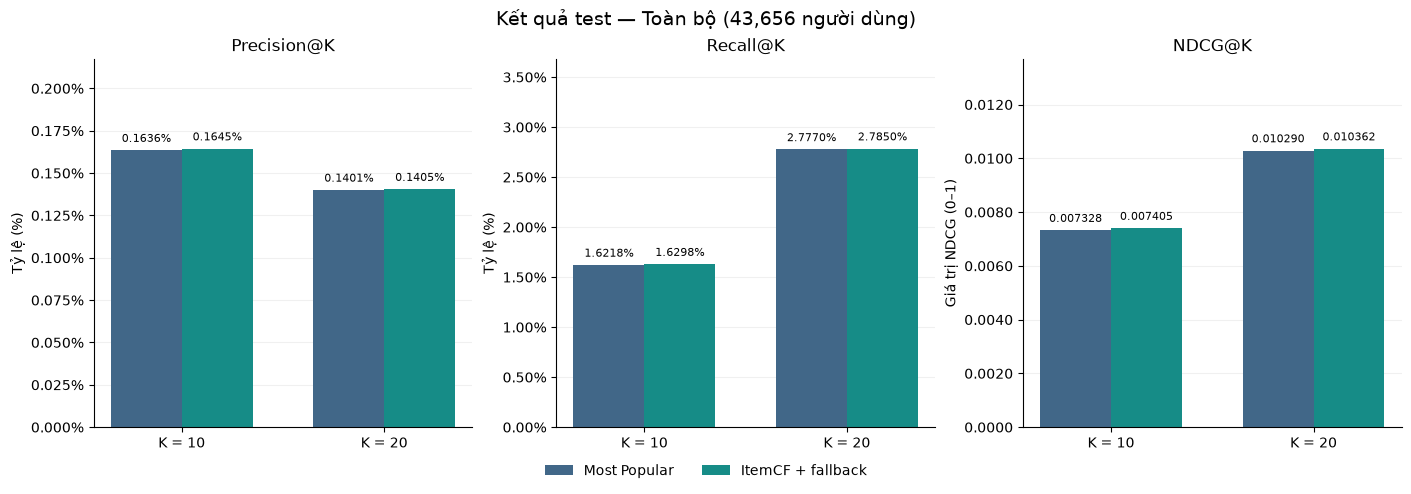

Đã lưu: reports\cf_presentation\figures\01_accuracy_all_users.png


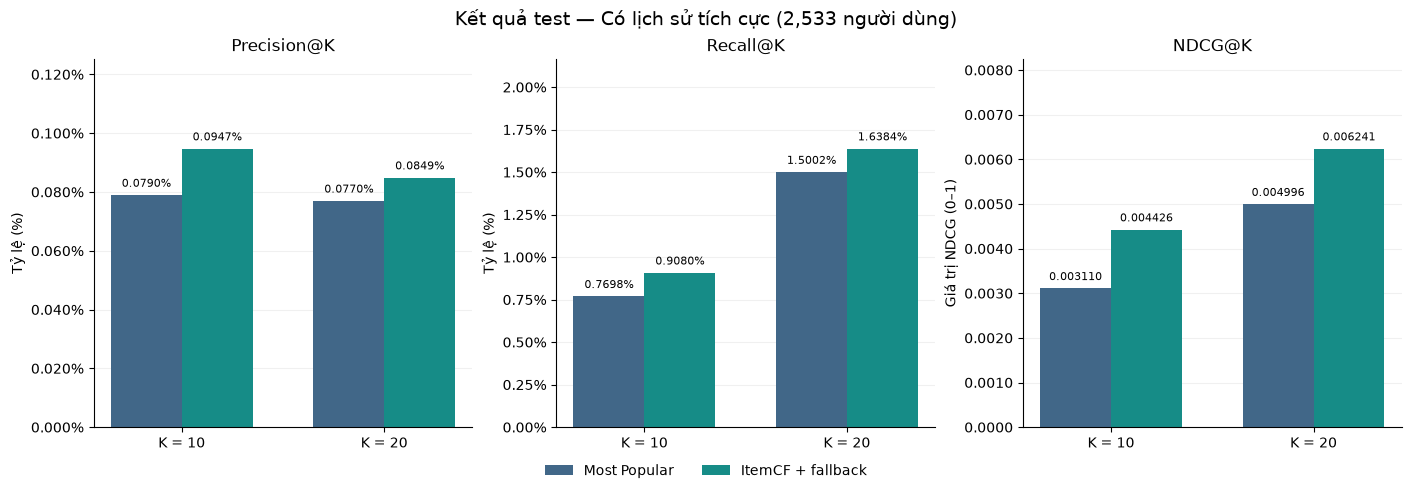

Đã lưu: reports\cf_presentation\figures\02_accuracy_positive_history.png


In [3]:
for group, filename in [(ALL_GROUP, '01_accuracy_all_users.png'),
                        (WARM_GROUP, '02_accuracy_positive_history.png')]:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout='constrained')
    x = np.arange(len(K_VALUES))
    width = 0.35
    users = int(test_results[(test_results['group'] == group) & (test_results.k == 10)].users.iloc[0])
    for ax, metric in zip(axes, ['Precision@K', 'Recall@K', 'NDCG@K']):
        peak = 0.0
        for offset, label in [(-width/2, POPULAR_LABEL), (width/2, CF_LABEL)]:
            values = (test_results[(test_results['group'] == group) & (test_results.model == label)]
                      .set_index('k').loc[list(K_VALUES), metric].to_numpy())
            bars = ax.bar(x + offset, values, width, color=COLORS[label], label=SHORT_NAMES[label])
            labels = [f'{value:.6f}' if metric == 'NDCG@K' else f'{100*value:.4f}%' for value in values]
            ax.bar_label(bars, labels=labels, padding=4, fontsize=8)
            peak = max(peak, float(values.max()))
        ax.set_title(metric)
        ax.set_xticks(x, [f'K = {k}' for k in K_VALUES])
        ax.set_ylim(0, max(peak * 1.32, 0.0001))
        ax.grid(axis='y', alpha=0.18)
        ax.set_axisbelow(True)
        if metric != 'NDCG@K':
            ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
            ax.set_ylabel('Tỷ lệ (%)')
        else:
            ax.yaxis.set_major_formatter(StrMethodFormatter('{x:.4f}'))
            ax.set_ylabel('Giá trị NDCG (0–1)')
    fig.suptitle(f'Kết quả test — {group} ({users:,} người dùng)', fontsize=14)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.08), ncols=2, frameon=False)
    save_figure(fig, filename)


## 3. Độ phủ sản phẩm trên cùng danh mục test

CatalogCoverage@K là số sản phẩm khác nhau xuất hiện trong các danh sách, chia cho số sản phẩm trong danh mục lịch sử. Biểu đồ dùng nhóm toàn bộ người dùng và cùng một mẫu số cho cả hai mô hình. Tăng độ phủ cho thấy nhiều sản phẩm được đưa vào danh sách hơn; chưa cho biết mức công bằng giữa các cửa hàng.


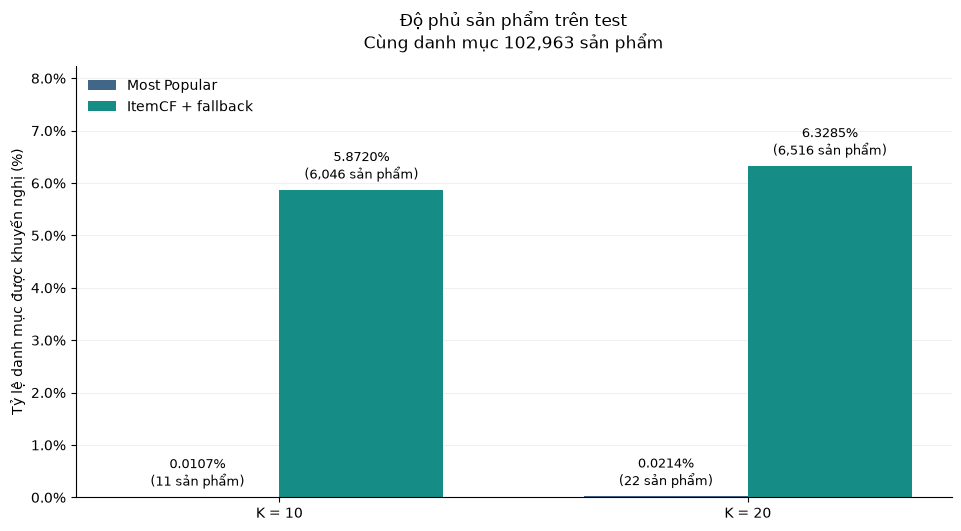

Đã lưu: reports\cf_presentation\figures\03_catalog_coverage.png


In [4]:
fig, ax = plt.subplots(figsize=(9.5, 5.2), layout='constrained')
x = np.arange(len(K_VALUES))
width = 0.35
max_coverage = 0.0
for offset, label in [(-width/2, POPULAR_LABEL), (width/2, CF_LABEL)]:
    values = (test_results[(test_results['group'] == ALL_GROUP) & (test_results.model == label)]
              .set_index('k').loc[list(K_VALUES), 'CatalogCoverage@K'].to_numpy())
    counts = np.rint(values * catalog_size).astype(int)
    if not np.allclose(values * catalog_size, counts, atol=1e-6):
        raise ValueError('Tỷ lệ độ phủ không khớp kích thước danh mục.')
    bars = ax.bar(x + offset, values, width, color=COLORS[label], label=SHORT_NAMES[label])
    ax.bar_label(bars, labels=[f'{100*v:.4f}%\n({n:,} sản phẩm)' for v, n in zip(values, counts)],
                 padding=5, fontsize=9)
    max_coverage = max(max_coverage, float(values.max()))
ax.set_xticks(x, [f'K = {k}' for k in K_VALUES])
ax.set_ylim(0, max(max_coverage * 1.3, 0.001))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_ylabel('Tỷ lệ danh mục được khuyến nghị (%)')
ax.set_title(f'Độ phủ sản phẩm trên test\nCùng danh mục {catalog_size:,} sản phẩm', pad=13)
ax.grid(axis='y', alpha=0.18)
ax.set_axisbelow(True)
ax.legend(loc='upper left', frameon=False)
save_figure(fig, '03_catalog_coverage.png')


## 4. Mức phụ thuộc vào Most Popular

Biểu đồ đếm tỷ lệ danh sách hoàn toàn lấy từ Most Popular ở K=10. Đây là tỷ lệ danh sách, khác với `CF_slot_fraction` là tỷ lệ vị trí do CF cung cấp. Hai chỉ số không cộng với nhau thành 100%.


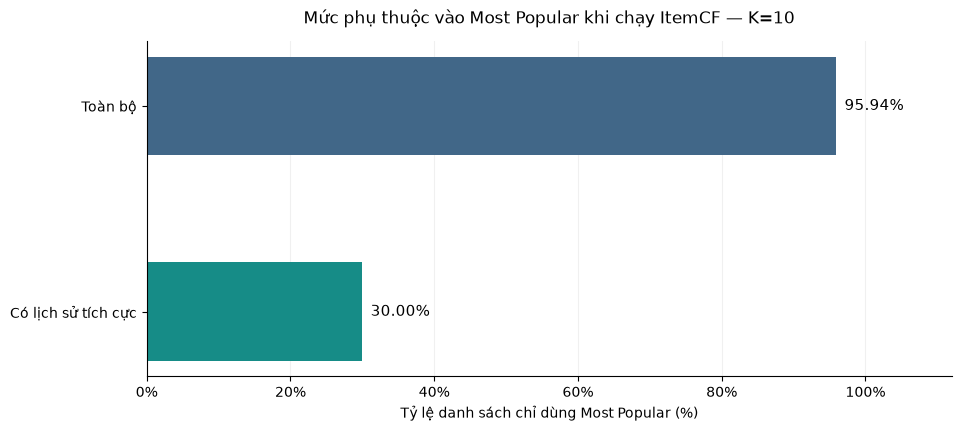

Đã lưu: reports\cf_presentation\figures\04_popular_only_lists.png


In [5]:
groups = [ALL_GROUP, WARM_GROUP]
fallback = (test_results[(test_results.model == CF_LABEL) & (test_results.k == 10)]
            .set_index('group').loc[groups, 'popular_only_list_fraction'].to_numpy())
fig, ax = plt.subplots(figsize=(9.5, 4.2), layout='constrained')
bars = ax.barh(groups, fallback, color=[COLORS[POPULAR_LABEL], COLORS[CF_LABEL]], height=0.48)
ax.bar_label(bars, labels=[f'{100*v:.2f}%' for v in fallback], padding=6, fontsize=11)
ax.set_xlim(0, 1.12)
ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.invert_yaxis()
ax.set_xlabel('Tỷ lệ danh sách chỉ dùng Most Popular (%)')
ax.set_title('Mức phụ thuộc vào Most Popular khi chạy ItemCF — K=10', pad=13)
ax.grid(axis='x', alpha=0.18)
ax.set_axisbelow(True)
save_figure(fig, '04_popular_only_lists.png')


## 5. Chênh lệch NDCG@10 và khoảng tin cậy

Sử dụng nguyên kết quả paired bootstrap ở notebook 03. Dấu chấm là trung bình NDCG@10 của CF trừ Most Popular; đoạn ngang là khoảng percentile 95%. Nếu đoạn này chứa mốc 0 thì chưa có bằng chứng rõ về cải thiện trong phép đánh giá hiện tại. Nhóm có lịch sử tích cực là tập con của nhóm toàn bộ, không phải một mẫu độc lập thứ hai.


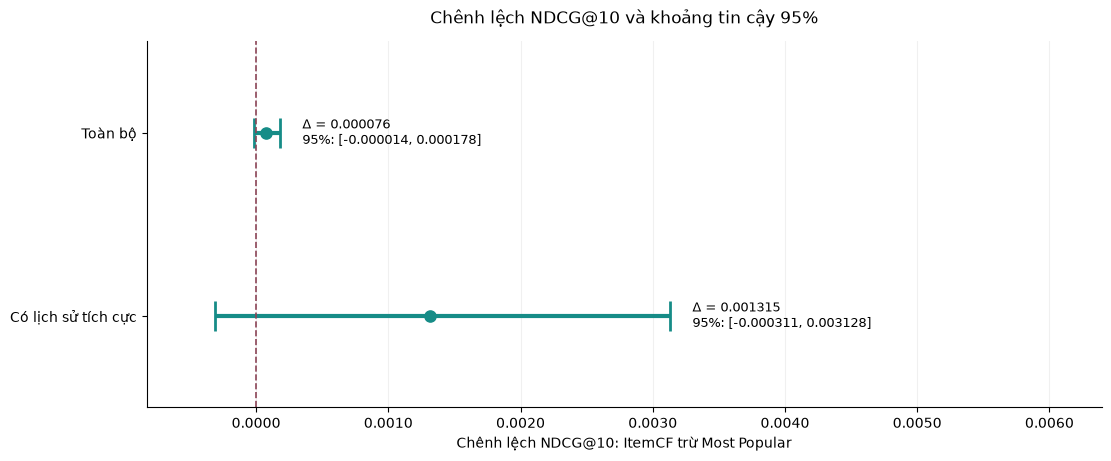

Đã lưu: reports\cf_presentation\figures\05_ndcg10_confidence_interval.png


In [6]:
ci = bootstrap_results.set_index('group').loc[[ALL_GROUP, WARM_GROUP]].reset_index()
if not np.isfinite(ci[['mean_NDCG_delta_CF_minus_Popular', 'CI95_low', 'CI95_high']].to_numpy()).all():
    raise ValueError('Khoảng tin cậy có giá trị không hợp lệ.')
if not (ci.CI95_low <= ci.CI95_high).all():
    raise ValueError('Cận dưới phải nhỏ hơn hoặc bằng cận trên.')
fig, ax = plt.subplots(figsize=(11, 4.5), layout='constrained')
span = max(float(ci.CI95_high.max() - ci.CI95_low.min()), 0.0001)
for position, row in ci.iterrows():
    low, high = float(row.CI95_low), float(row.CI95_high)
    point = float(row.mean_NDCG_delta_CF_minus_Popular)
    ax.hlines(position, low, high, color=COLORS[CF_LABEL], linewidth=3)
    ax.vlines([low, high], position-0.08, position+0.08, color=COLORS[CF_LABEL], linewidth=2)
    ax.scatter([point], [position], color=COLORS[CF_LABEL], s=65, zorder=3)
    ax.text(high+span*0.05, position,
             f'Δ = {point:.6f}\n95%: [{low:.6f}, {high:.6f}]', va='center', fontsize=9)
ax.axvline(0, color='#8B4456', linestyle='--', linewidth=1.2)
ax.set_yticks(np.arange(len(ci)), ci['group'].tolist())
ax.set_ylim(-0.5, len(ci)-0.5)
ax.invert_yaxis()
ax.set_xlim(min(float(ci.CI95_low.min()), 0)-span*0.15,
             max(float(ci.CI95_high.max()), 0)+span*0.95)
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:.4f}'))
ax.set_xlabel('Chênh lệch NDCG@10: ItemCF trừ Most Popular')
ax.set_title('Chênh lệch NDCG@10 và khoảng tin cậy 95%', pad=13)
ax.grid(axis='x', alpha=0.18)
ax.set_axisbelow(True)
save_figure(fig, '05_ndcg10_confidence_interval.png')


## 6. Nạp mô hình để tạo khuyến nghị

Ô này khai báo lớp chỉ phục vụ nạp và dự đoán. Danh sách được tạo bằng đúng quy tắc của notebook 03, gồm điểm cosine, loại sản phẩm đã đánh giá ở bất kỳ mức sao nào, phá hòa bằng ID và bổ sung bằng Most Popular.

Với ứng viên CF, có thể truy lại sản phẩm trong lịch sử tích cực đóng góp vào điểm. Khi có nhiều đóng góp, bảng hiển thị đóng góp cosine lớn nhất; điểm CF vẫn là tổng tất cả đóng góp. Đây là bằng chứng từ phép tính của mô hình, không phải lời giải thích do LLM sinh ra.


In [7]:
from pathlib import Path
from collections import defaultdict
import json
import numpy as np
import pandas as pd
from scipy import sparse


class SavedItemCF:
    """Load notebook 03 artifacts and predict without fitting a model."""

    @classmethod
    def load(cls, directory):
        directory = Path(directory)
        obj = cls()
        obj.config = json.loads((directory / 'model_config.json').read_text(encoding='utf-8'))
        obj.R = sparse.load_npz(directory / 'user_item_train.npz').tocsr()
        obj.S = sparse.load_npz(directory / 'item_neighbors.npz').tocsr()
        items = pd.read_csv(directory / 'items.csv', dtype={'parent_asin': 'string'},
                            keep_default_na=False).sort_values('item_index')
        user_file = directory / 'users.csv.gz'
        if not user_file.is_file():
            user_file = directory / 'users.csv'
        users = pd.read_csv(user_file, dtype={'user_id': 'string'},
                            keep_default_na=False).sort_values('user_index')
        if not np.array_equal(items.item_index.to_numpy(), np.arange(len(items))):
            raise ValueError('Ánh xạ item_index không liên tục. Lưu lại mô hình ở notebook 03.')
        if not np.array_equal(users.user_index.to_numpy(), np.arange(len(users))):
            raise ValueError('Ánh xạ user_index không liên tục. Lưu lại mô hình ở notebook 03.')
        obj.item_ids = pd.Index(items.parent_asin, name='parent_asin')
        obj.user_ids = pd.Index(users.user_id, name='user_id')
        obj.item_to_index = {v: i for i, v in enumerate(obj.item_ids)}
        obj.user_to_index = {v: i for i, v in enumerate(obj.user_ids)}
        if obj.R.shape != (len(obj.user_ids), len(obj.item_ids)):
            raise ValueError('Ma trận R và ánh xạ ID không khớp. Chạy lại ô lưu mô hình ở notebook 03.')
        if obj.S.shape != (len(obj.item_ids), len(obj.item_ids)):
            raise ValueError('Ma trận lân cận và ánh xạ sản phẩm không khớp.')
        obj.popularity = pd.read_csv(directory / 'popularity.csv',
                                      dtype={'parent_asin': 'string'}, keep_default_na=False)
        obj.popular_ids = obj.popularity.parent_asin.tolist()
        obj.positive_counts = dict(zip(obj.popularity.parent_asin,
                                       obj.popularity.positive_user_count.astype(int)))
        obj.seen = defaultdict(set)
        seen_file = directory / 'seen_history.csv.gz'
        if not seen_file.is_file():
            raise FileNotFoundError('Thiếu seen_history.csv.gz. Chạy ô lưu mô hình ở notebook 03.')
        seen = pd.read_csv(seen_file, dtype={'user_id': 'string', 'parent_asin': 'string'},
                            keep_default_na=False)
        for user, item in seen.itertuples(index=False, name=None):
            obj.seen[user].add(item)
        return obj

    def positive_history(self, user_id):
        index = self.user_to_index.get(user_id)
        columns = ['parent_asin', 'feedback_used_by_model']
        if index is None:
            return pd.DataFrame(columns=columns)
        items = self.R[index:index + 1].indices
        return pd.DataFrame({'parent_asin': self.item_ids[items],
                             'feedback_used_by_model': 'rating >= 4 trong lịch sử'})

    def recommend(self, user_id, k=10, use_cf=True):
        if k < 1 or int(k) != k:
            raise ValueError('K cần là số nguyên dương.')
        k = int(k)
        user_id = str(user_id)
        seen = self.seen.get(user_id, set())
        user_index = self.user_to_index.get(user_id)
        chosen, cf_scores = [], {}
        if use_cf and user_index is not None:
            scores = (self.R[user_index:user_index + 1] @ self.S).tocsr()
            candidates, values = scores.indices, scores.data
            keep = np.asarray([v > 0 and self.item_ids[i] not in seen
                               for i, v in zip(candidates, values)], dtype=bool)
            candidates, values = candidates[keep], values[keep]
            order = np.lexsort((candidates, -values))[:k]
            chosen = [self.item_ids[i] for i in candidates[order]]
            cf_scores = {self.item_ids[candidates[j]]: float(values[j]) for j in order}
        selected = set(chosen)
        for item in self.popular_ids:
            if len(chosen) >= k:
                break
            if item not in seen and item not in selected:
                chosen.append(item)
                selected.add(item)

        rows = []
        anchors = self.R[user_index:user_index + 1].indices if user_index is not None else np.array([], dtype=int)
        for rank, item in enumerate(chosen, start=1):
            anchor_id, anchor_cosine = '', np.nan
            if item in cf_scores:
                column = self.item_to_index[item]
                # This dense vector has one entry per positive-history product,
                # rather than one entry for every pair of catalog products.
                contributions = self.S[anchors, column].toarray().ravel()
                positive = contributions > 0
                if not positive.any():
                    raise ValueError('Ứng viên CF không có bằng chứng đóng góp dương.')
                active_anchors = anchors[positive]
                active_values = contributions[positive]
                best = np.lexsort((active_anchors, -active_values))[0]
                anchor_id = self.item_ids[active_anchors[best]]
                anchor_cosine = float(active_values[best])
                if not np.isclose(contributions.sum(), cf_scores[item], atol=1e-6):
                    raise ValueError('Tổng bằng chứng không khớp điểm CF.')
                source = 'ItemCF'
                note = 'Có độ tương tự cosine dương với sản phẩm đã đánh giá tích cực; hiển thị đóng góp lớn nhất.'
            else:
                source = 'Most Popular fallback' if use_cf else 'Most Popular'
                note = 'Xếp theo số người đánh giá tích cực trong train + validation, sau khi loại sản phẩm đã đánh giá.'
            rows.append({'rank': rank, 'parent_asin': item, 'source': source,
                         'cf_score': cf_scores.get(item, np.nan),
                         'positive_users_in_history': self.positive_counts.get(item, 0),
                         'evidence_parent_asin': anchor_id, 'evidence_cosine': anchor_cosine,
                         'evidence_note': note})
        result = pd.DataFrame(rows, columns=['rank', 'parent_asin', 'source', 'cf_score',
                                             'positive_users_in_history', 'evidence_parent_asin',
                                             'evidence_cosine', 'evidence_note'])
        assert len(result) <= k and result.parent_asin.is_unique
        assert set(result.parent_asin).isdisjoint(seen)
        assert set(result.parent_asin).issubset(self.item_to_index)
        return result


In [8]:
model = SavedItemCF.load(MODEL_DIR)
if model.config['n_neighbors'] != selection['selected_n_neighbors']:
    raise ValueError('Mô hình và cấu hình lựa chọn không khớp. Chạy lại notebook 03.')
if len(model.item_ids) != catalog_size:
    raise ValueError('Danh mục trong mô hình và bảng đánh giá không khớp.')
if model.config['history_end_timestamp_ms'] != test_diagnostics['history_end_timestamp_ms']:
    raise ValueError('Mốc lịch sử trong mô hình và đánh giá không khớp.')
saved_selection_hash = model.config.get('extra', {}).get('selection_sha256')
current_selection_hash = hashlib.sha256((SOURCE_REPORT_DIR / 'selected_config.json').read_bytes()).hexdigest()
if saved_selection_hash and saved_selection_hash != current_selection_hash:
    raise ValueError('Cấu hình đánh giá không thuộc bản mô hình đã lưu. Chạy lại notebook 03.')

for (user, k), block in saved_demo.groupby(['user_id', 'k'], sort=False):
    actual = model.recommend(user, int(k))
    expected = block.sort_values('rank')
    if actual.parent_asin.tolist() != expected.parent_asin.tolist() or actual.source.tolist() != expected.source.tolist():
        raise ValueError('Dự đoán không khớp ví dụ đã lưu ở notebook 03.')
print('Đã nạp mô hình và đối chiếu đúng danh sách Top-K với notebook 03.')


Đã nạp mô hình và đối chiếu đúng danh sách Top-K với notebook 03.


## 7. Tra cứu tên sản phẩm

Đọc **sheet `Product_Metadata`, cột `title`**. Trong sheet `Merged_Data`, cột `title` là tiêu đề review; tên sản phẩm ở cột `product_title`. Notebook này dùng sheet metadata để mỗi mã sản phẩm có đúng một dòng.

Bản metadata không có mốc hiệu lực theo thời gian cho tên sản phẩm. Tên chỉ phục vụ trình bày sau khi dự đoán; không được đưa vào mô hình, điểm số hay chọn tham số. Các tổng hợp như `rating_number` và `average_rating` trong metadata cũng không được dùng.


In [9]:
if METADATA_XLSX is not None:
    metadata_path = Path(METADATA_XLSX).expanduser()
    if not metadata_path.is_file():
        raise FileNotFoundError('Không tìm thấy METADATA_XLSX: ' + str(metadata_path))
else:
    candidates = [PROJECT_DIR / METADATA_FILENAME,
                  PROJECT_DIR / 'data' / METADATA_FILENAME,
                  PROJECT_DIR / 'data' / 'raw' / METADATA_FILENAME]
    metadata_path = next((p for p in candidates if p.is_file()), None)

source_info = None
if metadata_path is not None:
    stat = metadata_path.stat()
    source_info = {'schema_version': 1, 'filename': metadata_path.name,
                   'size_bytes': stat.st_size, 'modified_ns': stat.st_mtime_ns,
                   'sheet': 'Product_Metadata', 'id_column': 'parent_asin', 'title_column': 'title'}
cached_info = json.loads(TITLE_CACHE_INFO.read_text(encoding='utf-8')) if TITLE_CACHE_INFO.is_file() else None
use_cache = TITLE_CACHE.is_file() and (metadata_path is None or source_info == cached_info)

if use_cache:
    product_titles = pd.read_csv(TITLE_CACHE, dtype='string', keep_default_na=False)
    metadata_status = 'Đã dùng bản tra cứu tên sản phẩm được lưu từ lần đọc Excel trước.'
elif metadata_path is not None:
    print('Đang đọc sheet Product_Metadata; lần đầu có thể mất một lúc...', flush=True)
    product_titles = pd.read_excel(metadata_path, sheet_name='Product_Metadata',
                                   usecols=['parent_asin', 'title'],
                                   dtype={'parent_asin': 'string', 'title': 'string'},
                                   keep_default_na=False, engine='openpyxl')
    product_titles = product_titles.rename(columns={'title': 'product_title'})
    product_titles['parent_asin'] = product_titles['parent_asin'].str.strip()
    product_titles['product_title'] = product_titles['product_title'].str.strip()
    if product_titles.parent_asin.eq('').any() or product_titles.parent_asin.duplicated().any():
        raise ValueError('Metadata cần một dòng cho mỗi parent_asin không rỗng.')
    product_titles.to_csv(TITLE_CACHE, index=False, compression='gzip')
    TITLE_CACHE_INFO.write_text(json.dumps(source_info, ensure_ascii=False, indent=2), encoding='utf-8')
    metadata_status = 'Đã đọc tên sản phẩm từ Product_Metadata và lưu bản tra cứu.'
else:
    product_titles = pd.DataFrame({'parent_asin': pd.Series(dtype='string'),
                                   'product_title': pd.Series(dtype='string')})
    metadata_status = ('Chưa tìm thấy Excel hoặc bản tra cứu. Đặt All_Beauty_Cleaned_Merged.xlsx vào '
                       'thư mục dự án/data/raw, hoặc sửa METADATA_XLSX rồi chạy lại các ô từ bước 7.')

if not {'parent_asin', 'product_title'}.issubset(product_titles.columns):
    raise ValueError('Bản tra cứu tên sản phẩm không đúng cấu trúc.')
if product_titles.parent_asin.duplicated().any():
    raise ValueError('Bản tra cứu có parent_asin trùng; cần tạo lại từ Excel.')
print(metadata_status)
print(f'Có {len(product_titles):,} dòng tra cứu tên sản phẩm.')


def attach_titles(frame):
    original_ids = frame.parent_asin.tolist()
    result = frame.merge(product_titles, on='parent_asin', how='left', validate='many_to_one', sort=False)
    if result.parent_asin.tolist() != original_ids:
        raise ValueError('Ghép tên làm thay đổi thứ tự sản phẩm.')
    result['product_title'] = result['product_title'].fillna('').replace('', '(Chưa có tên sản phẩm)')
    if 'evidence_parent_asin' in result:
        anchors = product_titles.rename(columns={'parent_asin': 'evidence_parent_asin',
                                                 'product_title': 'evidence_product_title'})
        result = result.merge(anchors, on='evidence_parent_asin', how='left', validate='many_to_one', sort=False)
        result['evidence_product_title'] = result['evidence_product_title'].fillna('')
        if result.parent_asin.tolist() != original_ids:
            raise ValueError('Ghép tên bằng chứng làm thay đổi thứ tự sản phẩm.')
    return result


Đang đọc sheet Product_Metadata; lần đầu có thể mất một lúc...
Đã đọc tên sản phẩm từ Product_Metadata và lưu bản tra cứu.
Có 112,590 dòng tra cứu tên sản phẩm.


## 8. Chọn người dùng và xem Top-K

Để chạy ví dụ mặc định, giữ `DEMO_USER_ID = None`. Notebook chọn người có ít nhất một ứng viên CF trong ví dụ đã lưu ở bước 03; việc chọn ví dụ không dựa trên số hit hoặc điểm test của người đó.

Để xem người khác, gán ID vào `DEMO_USER_ID`, chọn `DEMO_K = 10` hoặc `20` rồi chạy lại ô này. Có thể thử `DEMO_USER_ID = '__new_user__'` để xem trường hợp người mới. Ô này cập nhật các tệp `demo_cf_top_k.csv`, `demo_popular_top_k.csv` và `demo_positive_history.csv` theo người đang chọn.

`cf_score` là tổng cosine, không phải xác suất mua hàng. Cột `positive_users_in_history` được tính từ lịch sử train + validation, không phải số đánh giá tổng hợp trong metadata. Sản phẩm trong lịch sử được ghi nhận là đã đánh giá tích cực; dữ liệu không xác nhận đây là lượt mua.


In [10]:
DEMO_USER_ID = None
DEMO_K = 10

if DEMO_K not in K_VALUES:
    raise ValueError('Chọn DEMO_K = 10 hoặc 20 để khớp kết quả đánh giá.')
if DEMO_USER_ID is None:
    candidates = saved_demo[saved_demo.source == 'ItemCF']
    demo_user = str(candidates.iloc[0].user_id if not candidates.empty else saved_demo.iloc[0].user_id)
else:
    demo_user = str(DEMO_USER_ID).strip()

history_table = attach_titles(model.positive_history(demo_user))
cf_table = attach_titles(model.recommend(demo_user, DEMO_K, use_cf=True))
popular_table = attach_titles(model.recommend(demo_user, DEMO_K, use_cf=False))
cf_table.insert(0, 'user_id', demo_user)
popular_table.insert(0, 'user_id', demo_user)
history_table.insert(0, 'user_id', demo_user)

history_table.to_csv(REPORT_DIR / 'demo_positive_history.csv', index=False, encoding='utf-8-sig')
cf_table.to_csv(REPORT_DIR / 'demo_cf_top_k.csv', index=False, encoding='utf-8-sig')
popular_table.to_csv(REPORT_DIR / 'demo_popular_top_k.csv', index=False, encoding='utf-8-sig')
print('Người dùng:', demo_user)
print('Sản phẩm đã đánh giá trong lịch sử, mọi mức sao:', len(model.seen.get(demo_user, set())))
print('Sản phẩm tích cực được mô hình dùng:', len(history_table))
print('Số vị trí lấy từ CF trong ví dụ:', int(cf_table.source.eq('ItemCF').sum()))
print('Lịch sử tích cực dùng để dự đoán:')
display(history_table[['parent_asin', 'product_title', 'feedback_used_by_model']].head(20))
print('ItemCF + Popular fallback:')
display(cf_table[['rank', 'parent_asin', 'product_title', 'source', 'cf_score',
                  'evidence_product_title', 'evidence_cosine']].round(6))
print('Most Popular cho cùng người dùng:')
display(popular_table[['rank', 'parent_asin', 'product_title', 'positive_users_in_history']])


Người dùng: AHOUEEGPXZY52O7RHMG5VR76IKJA
Sản phẩm đã đánh giá trong lịch sử, mọi mức sao: 1
Sản phẩm tích cực được mô hình dùng: 1
Số vị trí lấy từ CF trong ví dụ: 1
Lịch sử tích cực dùng để dự đoán:


,parent_asin,product_title,feedback_used_by_model
0,B009NGDFSG,Red Crystal Bronze Metal Alloy flower / butterfly hair claws & clips by unbrand,rating >= 4 trong lịch sử


ItemCF + Popular fallback:


,rank,parent_asin,product_title,source,cf_score,evidence_product_title,evidence_cosine
0,1,B00ZORYBVI,Gellen Color Changing Temperature Gel Nail Polish 4 Colors Set - Nail Art Fun Hom...,ItemCF,0.111111,Red Crystal Bronze Metal Alloy flower / butterfly hair claws & clips by unbrand,0.111111
1,2,B085BB7B1M,Salux Nylon Japanese Beauty Skin Bath Wash Cloth/towel (3) Blue Yellow and Pink,Most Popular fallback,NaN,,NaN
2,3,B0BM4GX6TT,"Godefroy Tint Kit for Spot Coloring, Dark Brown",Most Popular fallback,NaN,,NaN
3,4,B07C533XCW,Segbeauty empty bottle 160083,Most Popular fallback,NaN,,NaN
4,5,B09X9BG4FC,Makone Crystal Crowns and Tiaras with Comb Headband for Girl or Women Birthday Pa...,Most Popular fallback,NaN,,NaN
5,6,B00R1TAN7I,GranNaturals Boar Bristle Smoothing Hair Brush for Women and Men - Medium/Soft Br...,Most Popular fallback,NaN,,NaN
6,7,B0C9CWKY9G,Picoway 20 Pack Mouse Ears Solid Black and Red Bow Headband,Most Popular fallback,NaN,,NaN
7,8,B01M1OFZOG,"Bed Head Curve Check Curling Wand for Tousled Waves and Texture, Jumbo Barrel",Most Popular fallback,NaN,,NaN
8,9,B0107QYW14,Harlorki Women's Bohemian Jewelry Statement Necklaces Women Rhinestone Gem Pendan...,Most Popular fallback,NaN,,NaN
9,10,B09C2ZW2GL,Tigi Bedhead Hard Head Hairspray (6 Pack),Most Popular fallback,NaN,,NaN


Most Popular cho cùng người dùng:


,rank,parent_asin,product_title,positive_users_in_history
0,1,B085BB7B1M,Salux Nylon Japanese Beauty Skin Bath Wash Cloth/towel (3) Blue Yellow and Pink,1713
1,2,B0BM4GX6TT,"Godefroy Tint Kit for Spot Coloring, Dark Brown",1264
2,3,B07C533XCW,Segbeauty empty bottle 160083,1178
3,4,B09X9BG4FC,Makone Crystal Crowns and Tiaras with Comb Headband for Girl or Women Birthday Pa...,1011
4,5,B00R1TAN7I,GranNaturals Boar Bristle Smoothing Hair Brush for Women and Men - Medium/Soft Br...,984
5,6,B0C9CWKY9G,Picoway 20 Pack Mouse Ears Solid Black and Red Bow Headband,917
6,7,B01M1OFZOG,"Bed Head Curve Check Curling Wand for Tousled Waves and Texture, Jumbo Barrel",794
7,8,B0107QYW14,Harlorki Women's Bohemian Jewelry Statement Necklaces Women Rhinestone Gem Pendan...,775
8,9,B09C2ZW2GL,Tigi Bedhead Hard Head Hairspray (6 Pack),721
9,10,B005BZQHEC,Gauge Gear Ear Stretching Balm | 10 ml Jar | Piercing Aftercare | Stretched or Da...,720


## 9. Xuất bảng và gợi ý nội dung báo cáo

Phần này chỉ định dạng các chỉ số đã có; không tính lại hoặc chọn lại mô hình. Bảng CSV cho báo cáo ghi rõ đơn vị phần trăm trong tên cột. Bản `presentation_notes.md` liên kết đến năm biểu đồ và các tệp ví dụ đã tạo.


In [11]:
report_table = test_results[['model', 'k', 'group', 'users', 'Precision@K', 'Recall@K',
                              'NDCG@K', 'CatalogCoverage@K']].copy()
for name in ['Precision@K', 'Recall@K', 'CatalogCoverage@K']:
    report_table[name + ' (%)'] = 100 * report_table.pop(name)
report_table.to_csv(REPORT_DIR / 'test_table_for_report.csv', index=False, encoding='utf-8-sig')

pop = test_results[(test_results.model == POPULAR_LABEL) & (test_results.k == 10)
                   & (test_results['group'] == ALL_GROUP)].iloc[0]
cf = test_results[(test_results.model == CF_LABEL) & (test_results.k == 10)
                  & (test_results['group'] == ALL_GROUP)].iloc[0]
all_ci = ci[ci['group'] == ALL_GROUP].iloc[0]
includes_zero = all_ci.CI95_low <= 0 <= all_ci.CI95_high
if includes_zero:
    conclusion = 'Khoảng tin cậy 95% chứa 0, vì vậy chưa có bằng chứng rõ về cải thiện NDCG@10 trong phép đánh giá hiện tại.'
elif all_ci.CI95_low > 0:
    conclusion = 'Khoảng tin cậy 95% nằm trên 0; NDCG@10 của CF cao hơn Most Popular trong phép đánh giá hiện tại.'
else:
    conclusion = 'Khoảng tin cậy 95% nằm dưới 0; NDCG@10 của CF thấp hơn Most Popular trong phép đánh giá hiện tại.'

pop_items = int(round(pop['CatalogCoverage@K'] * catalog_size))
cf_items = int(round(cf['CatalogCoverage@K'] * catalog_size))
unseen_share = test_diagnostics['positive_pairs_with_items_unseen_in_history'] / test_diagnostics['novel_positive_pairs']
notes = f'''# Kết quả hướng 1 — Gợi ý trình bày\n\nNgười thực hiện: Cường Quốc.\n\n'''
notes += f'''## 1. Mục tiêu và đầu ra\n\nXây dựng mô hình lọc cộng tác tạo Top-10/Top-20 sản phẩm chưa được người dùng đánh giá trong lịch sử, so sánh với Most Popular và tạo chuẩn so sánh cho các hướng KG/LLM. Mục tiêu kinh doanh của toàn đề tài là giúp cửa hàng tiếp cận khách hàng; phần này đo các chỉ số offline ở cấp sản phẩm.\n\n'''
notes += f'''## 2. Thiết kế thực nghiệm\n\n- Chia dữ liệu theo thời gian toàn cục bằng mốc đã lưu ở notebook 01.\n- Relevance là review từ 4 sao; mỗi cặp tích cực được dùng một lần khi huấn luyện.\n- Chọn N={selection['selected_n_neighbors']} trên validation theo NDCG@10, rồi huấn luyện lại bằng train + validation.\n- Cả hai mô hình dùng cùng danh mục {catalog_size:,} sản phẩm và cùng nhóm {int(pop['users']):,} người dùng test đủ điều kiện.\n- Loại sản phẩm đã đánh giá ở mọi mức sao; giữ sản phẩm chưa thấy trong lịch sử ở ground truth. Lịch sử được cố định trong giai đoạn test.\n\n'''
notes += f'''## 3. Kết quả chính ở K=10, toàn bộ người dùng\n\n| Chỉ số | Most Popular | ItemCF + fallback |\n| --- | --- | --- |\n| Precision@10 | {100*pop['Precision@K']:.4f}% | {100*cf['Precision@K']:.4f}% |\n| Recall@10 | {100*pop['Recall@K']:.4f}% | {100*cf['Recall@K']:.4f}% |\n| NDCG@10 | {pop['NDCG@K']:.8f} | {cf['NDCG@K']:.8f} |\n| Độ phủ danh mục | {100*pop['CatalogCoverage@K']:.4f}% ({pop_items:,} SP) | {100*cf['CatalogCoverage@K']:.4f}% ({cf_items:,} SP) |\n\n{conclusion} Trung bình chênh lệch NDCG@10 là {all_ci.mean_NDCG_delta_CF_minus_Popular:.8f}; khoảng 95% [{all_ci.CI95_low:.8f}, {all_ci.CI95_high:.8f}].\n\n'''
notes += f'''## 4. Diễn giải giới hạn và ví dụ\n\n- Ở K=10, {100*cf['popular_only_list_fraction']:.2f}% danh sách CF hoàn toàn dùng Most Popular. CF chỉ cung cấp {100*cf['CF_slot_fraction']:.2f}% tổng số vị trí trong nhóm toàn bộ.\n- {100*unseen_share:.2f}% cặp tích cực mới trong test có sản phẩm chưa có trong lịch sử. Mô hình CF hiện tại không đưa được những sản phẩm đó vào danh sách.\n- Khoảng tin cậy bootstrap mô tả lấy mẫu người dùng test hiện tại, không gồm bất định khi huấn luyện lại hoặc thay đổi thời gian.\n- Độ phủ sản phẩm tăng chưa chứng minh công bằng theo cửa hàng, tăng lượt mua hoặc tăng doanh thu. Để kiểm chứng mục tiêu kinh doanh cần ID cửa hàng và dữ liệu hiển thị/click/mua cùng thí nghiệm phù hợp.\n- Ví dụ Top-K minh họa cách mô hình xếp hạng; không dùng một ví dụ để thay thế kết quả trên toàn bộ test.\n- Bằng chứng CF là sản phẩm lịch sử có đóng góp cosine dương. Điểm CF không phải xác suất mua; tên metadata chỉ dùng để trình bày sau khi dự đoán.\n\n'''
notes += '''## 5. Tệp dùng khi báo cáo\n\n- `test_table_for_report.csv`: hai mô hình, hai mức K, hai nhóm; tên cột ghi rõ đơn vị.\n- `demo_cf_top_k.csv`: sản phẩm, tên, nguồn, điểm CF và bằng chứng.\n- `demo_popular_top_k.csv`: Most Popular cho cùng người dùng.\n- `demo_positive_history.csv`: các sản phẩm tích cực đã dùng cho ví dụ.\n\n'''
for name, caption in [
    ('01_accuracy_all_users.png', 'Độ chính xác — toàn bộ người dùng'),
    ('02_accuracy_positive_history.png', 'Độ chính xác — người có lịch sử tích cực'),
    ('03_catalog_coverage.png', 'Độ phủ sản phẩm trên cùng danh mục'),
    ('04_popular_only_lists.png', 'Mức phụ thuộc vào Most Popular'),
    ('05_ndcg10_confidence_interval.png', 'Chênh lệch NDCG@10 và khoảng tin cậy')]:
    notes += f'### {caption}\n\n![{caption}](figures/{name})\n\n'

(REPORT_DIR / 'presentation_notes.md').write_text(notes, encoding='utf-8')
manifest = {'selected_n_neighbors': int(selection['selected_n_neighbors']),
             'source_selection_sha256': current_selection_hash,
             'chart_files': sorted(p.name for p in CHART_DIR.glob('*.png')),
             'metadata_status': metadata_status, 'metadata_lookup_rows': len(product_titles),
             'demo_user_id': demo_user, 'demo_k': DEMO_K,
             'demo_cf_positions': int(cf_table.source.eq('ItemCF').sum()),
             'demo_missing_product_titles': int(cf_table.product_title.eq('(Chưa có tên sản phẩm)').sum())}
(REPORT_DIR / 'presentation_manifest.json').write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
print(conclusion)
print('Đã tạo 5 biểu đồ, bảng kết quả và ví dụ có bằng chứng tại:', REPORT_DIR)
print('Mở presentation_notes.md để xem gợi ý trình bày.')


Khoảng tin cậy 95% chứa 0, vì vậy chưa có bằng chứng rõ về cải thiện NDCG@10 trong phép đánh giá hiện tại.
Đã tạo 5 biểu đồ, bảng kết quả và ví dụ có bằng chứng tại: d:\Tài Liệu\RecommenderSystem\reports\cf_presentation
Mở presentation_notes.md để xem gợi ý trình bày.
